# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [15]:
ROLL_NO = 1024170348       # <-- your full roll number
NAME = "Akshat Prakash Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [16]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [17]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [18]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170348   Name: Akshat Prakash Singh   Fingerprint: EDC3ED9A   Tickets: 15

Ticket_ID                                                                         Ticket_Text
      T01                                    The LMS has stopped syncing. Can you check this?
      T02                  Laptop was working yesterday after the latest update. Please help.
      T03                                                Python 3.12 was installed yesterday.
      T04                Password failed to open after resetting my password. This is urgent.
      T05                       The printer crashes while opening. Is there another solution?
      T06             Password is running slowly while uploading the file. Please resolve it.
      T07 I reinstalled the email after restarting the system. The same problem occurs again.
      T08           Password is running slowly while uploading the file. It worked yesterday.
      T09                        I reinstalled the e-mail sinc

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [19]:
# Your code
# Q1. Preprocessing pipeline
rows = []

for _, r in df.iterrows():
    p = process_ticket(r["Ticket_Text"])
    rows.append({
        "Ticket_ID": r["Ticket_ID"],
        "Sentences": p["sentences"],
        "Tokens": p["tokens"],
        "Punctuation": p["punct"],
        "Stopwords": p["stops"],
        "Unique Tokens": list(set(p["tokens"])),
        "Final Tokens": p["final"]
    })

result = pd.DataFrame(rows)
result.loc[len(result)] = [
    "TOTAL",
    sum(map(len, result["Sentences"])),
    sum(map(len, result["Tokens"])),
    sum(map(len, result["Punctuation"])),
    sum(map(len, result["Stopwords"])),
    len(set(t for x in result["Tokens"] for t in x)),
    sum(map(len, result["Final Tokens"]))
]

display(result)




,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,"[The LMS has stopped syncing., Can you check t...","[the, lms, has, stopped, syncing, ., can, you,...","[., ?]","[the, has, can, you, this]","[the, stopped, lms, you, can, check, ., this, ...","[lms, stopped, syncing, check]"
1,T02,[Laptop was working yesterday after the latest...,"[laptop, was, working, yesterday, after, the, ...","[., .]","[was, after, the]","[yesterday, latest, working, the, laptop, ., a...","[laptop, working, yesterday, latest, update, p..."
2,T03,[Python 3.12 was installed yesterday.],"[python, 3.12, was, installed, yesterday, .]",[.],[was],"[yesterday, installed, 3.12, ., python, was]","[python, 3.12, installed, yesterday]"
3,T04,[Password failed to open after resetting my pa...,"[password, failed, to, open, after, resetting,...","[., .]","[to, after, my, this, is]","[my, this, ., after, to, open, resetting, urge...","[password, failed, open, resetting, password, ..."
4,T05,"[The printer crashes while opening., Is there ...","[the, printer, crashes, while, opening, ., is,...","[., ?]","[the, while, is, there]","[crashes, the, another, solution, ., opening, ...","[printer, crashes, opening, another, solution]"
5,T06,[Password is running slowly while uploading th...,"[password, is, running, slowly, while, uploadi...","[., .]","[is, while, the, it]","[the, running, please, ., file, it, is, slowly...","[password, running, slowly, uploading, file, p..."
6,T07,[I reinstalled the email after restarting the ...,"[i, reinstalled, the, email, after, restarting...","[., .]","[i, the, after, the, the, same, again]","[the, restarting, ., after, reinstalled, syste...","[reinstalled, email, restarting, system, probl..."
7,T08,[Password is running slowly while uploading th...,"[password, is, running, slowly, while, uploadi...","[., .]","[is, while, the, it]","[yesterday, the, running, ., file, worked, it,...","[password, running, slowly, uploading, file, w..."
8,T09,"[I reinstalled the e-mail since yesterday., Pl...","[i, reinstalled, the, e-mail, since, yesterday...","[., .]","[i, the, it]","[yesterday, the, e-mail, ., reinstalled, it, s...","[reinstalled, e-mail, since, yesterday, please..."
9,T10,[I couldn't connect to the password after rest...,"[i, could, n't, connect, to, the, password, af...","[., .]","[i, to, the, after, the]","[could, the, restarting, please, n't, ., after...","[could, n't, connect, password, restarting, sy..."


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* These tokens appear because word_tokenize() splits contractions into separate tokens

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [20]:

# Q2. Regular Expressions
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

patterns = {
    "Words > 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:[.,]\d+)*\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with vowel": r"\b[aeiouAEIOU][a-zA-Z]*\b"
}

for text in df["Ticket_Text"].tolist() + TEST_LINES:
    print("\nText:", text)
    for name, pattern in patterns.items():
        print(name + ":", re.findall(pattern, text))

    cleaned = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
                     "<EMAIL>", text)
    cleaned = re.sub(r"https?://\S+|www\.\S+", "<URL>", cleaned)
    cleaned = re.sub(r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d[- ]?){7,}\d(?!\w)",
                     "<PHONE>", cleaned)
    print("Cleaned:", cleaned)




# Your code


Text: The LMS has stopped syncing. Can you check this?
Words > 5 letters: ['stopped', 'syncing']
Numbers: []
Capitalized words: ['The', 'LMS', 'Can']
Words starting with vowel: []
Cleaned: The LMS has stopped syncing. Can you check this?

Text: Laptop was working yesterday after the latest update. Please help.
Words > 5 letters: ['Laptop', 'working', 'yesterday', 'latest', 'update', 'Please']
Numbers: []
Capitalized words: ['Laptop', 'Please']
Words starting with vowel: ['after', 'update']
Cleaned: Laptop was working yesterday after the latest update. Please help.

Text: Python 3.12 was installed yesterday.
Words > 5 letters: ['Python', 'installed', 'yesterday']
Numbers: ['3.12']
Capitalized words: ['Python']
Words starting with vowel: ['installed']
Cleaned: Python 3.12 was installed yesterday.

Text: Password failed to open after resetting my password. This is urgent.
Words > 5 letters: ['Password', 'failed', 'resetting', 'password', 'urgent']
Numbers: []
Capitalized words: ['Passwor

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [21]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://\S+|www\.\S+|[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}|(?:\+\d{1,3}[- ]?)?(?:\d[- ]?){7,}\d|\d+(?:\.\d+)+|\d+(?:,\d{3})+|\d+|[A-Za-z]+(?:['’-][A-Za-z]+)*"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for text in TEST_LINES + df["Ticket_Text"].tolist():
    print("\nText:", text)
    print("Custom:", my_tokenize(text))
    print("NLTK:  ", word_tokenize(text))






Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1,250']
NLTK:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 15

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [22]:
# Your code

# Compare stemming and lemmatization
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex = RegexpStemmer(r"(ing|ed|ly|s)$", min=4)
lemma = WordNetLemmatizer()

words = sorted(set(t for text in df["Ticket_Text"]
                   for t in process_ticket(text)["final"]))

def get_pos(word):
    tag = pos_tag([word])[0][1][0]
    return {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag, "n")

rows = []
for w in words:
    p, l, r = porter.stem(w), lancaster.stem(w), regex.stem(w)
    lm = lemma.lemmatize(w, get_pos(w))
    if len({p, l, r, lm}) > 1:
        rows.append([w, p, l, r, lm])

result = pd.DataFrame(rows, columns=[
    "Word", "Porter", "Lancaster", "Regexp", "WordNet Lemma"
])
display(result)


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,anything,anyth,anyth,anyth,anything
2,call,call,cal,call,call
3,change,chang,chang,change,change
4,computer,comput,comput,computer,computer
5,crashes,crash,crash,crashe,crash
6,file,file,fil,file,file
7,installed,instal,instal,install,instal
8,latest,latest,latest,latest,late
9,lms,lm,lms,lms,lm


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer: reinstalled → reinstal, crashes → crashes

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1 Tokens: 182 Unique: 89 TTR: 0.489
S2 Tokens: 153 Unique: 85 TTR: 0.5556
S3 Tokens: 88 Unique: 60 TTR: 0.6818
S4 Tokens: 88 Unique: 57 TTR: 0.6477

Top 10 S1: [('.', 24), ('the', 14), ('is', 6), ('i', 6), ('after', 5), ('password', 5), ('yesterday', 4), ('please', 4), ('it', 4), ('lms', 3)]
Top 10 S3: [('password', 5), ('yesterday', 4), ('please', 4), ('lms', 3), ("n't", 3), ('check', 2), ('working', 2), ('latest', 2), ('update', 2), ('help', 2)]


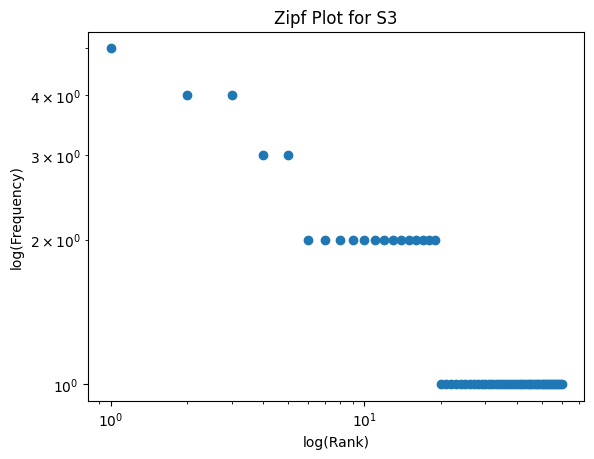


Top 5 S1 bigrams: [(('.', 'i'), 5), (('.', 'please'), 4), (('the', 'lms'), 3), (('yesterday', '.'), 3), (('.', 'the'), 3)]
Top 5 S3 bigrams: [(('latest', 'update'), 2), (('please', 'help'), 2), (('password', 'running'), 2), (('running', 'slowly'), 2), (('slowly', 'uploading'), 2)]


In [23]:
# Your code

# S1-S4: Vocabulary, Zipf plot, and bigrams
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()
texts = df["Ticket_Text"].tolist()

S1 = [t for text in texts for t in process_ticket(text)["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for text in texts for t in process_ticket(text)["final"]]
S4 = [porter.stem(t) for t in S3]

for name, tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    print(name, "Tokens:", len(tokens),
          "Unique:", len(set(tokens)),
          "TTR:", round(len(set(tokens)) / len(tokens), 4))

print("\nTop 10 S1:", Counter(S1).most_common(10))
print("Top 10 S3:", Counter(S3).most_common(10))

freq = Counter(S3).most_common()
plt.plot(range(1, len(freq)+1), [f for _, f in freq], "o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Zipf Plot for S3")
plt.show()

print("\nTop 5 S1 bigrams:", Counter(bigrams(S1)).most_common(5))
print("Top 5 S3 bigrams:", Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR depends on the ratio of unique tokens to total tokens. Stemming generally reduces vocabulary diversity by merging word forms, but the exact TTR change depends on the dataset.